In [1]:
# Basic libraries for PyTorch deep learning 
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

import nibabel as nib #MRI Image processing library, reads .nii files

# sklearn train test split and evaluation metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    roc_auc_score
)

# These functions are used for preprocessing the data before model inferencing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

# Generic libraries, pls dont question their existence
import pandas as pd
import numpy as np
import os

In [2]:
def metadata_preprocessing(file_path:str = "raw/oasis_cross-sectional.csv") -> pd.DataFrame:
    """
    This function takes in a file path to a CSV file containing metadata and performs preprocessing steps on it.

    The file is located in the 'raw' directory of the project. The preprocessing steps include:
        - One hot encoding categorical variables
        - Removal of columns with significant missing values
        - KNN Imputation for missing values
        - Combining rare classes in the target variable to avoid class imbalance issues
        - Adding .nii file paths to the metadata for easier access to MRI images
        - Splitting of ID column into subject_id and session columns for better organization

    Args:
        file_path (str): The path to the CSV file containing metadata.
    Returns:
        metadata (pd.DataFrame): A preprocessed DataFrame containing the metadata.
    """

    metadata = pd.read_csv(file_path)
    imputer = KNNImputer(n_neighbors=5)
    scaler = StandardScaler()

    # Delay column had 95.4% missing values and was irrelevant to study
    # Hand was dropped as everyone was right-handed, not useful for analysis
    metadata = metadata.drop(columns = ["Delay", "Hand"])

    # Created binary columns for gender and dropped original column (One Hot Encoding)
    metadata['male'] = (metadata['M/F'] == 'M').astype(int)
    metadata['female'] = (metadata['M/F'] == 'F').astype(int)
    metadata = metadata.drop(columns = "M/F")

    # CDR of 2 i.e moderate dementia is very rare in the dataset, so we will combine it with CDR of 1 i.e mild dementia
    # Avoids serious class imbalance issues and allows for better model training
    metadata.loc[metadata['CDR'] == 2.0, 'CDR'] = 1

    # Performing class remappint with the following mapping -> {non-demented:0, mild demented:1, demented:1}
    remapping = {0.0: 0, 0.5: 1, 1.0: 1}
    metadata["CDR"] = metadata["CDR"].map(lambda x : remapping[x])

    # Extraction of subject id and session id and storing separately from the metadata
    subject_id = metadata["ID"].map(lambda x : "_".join(x.split("_")[:2]))
    session = metadata["ID"].map(lambda x : x.split("_")[-1])

    # Extracting data path from labels to easily access the MRI images for training and testing
    mapping:dict[str, str] = {}
    files:list[str] = os.listdir("raw/oasis/OASIS")

    for file in files:
        uid = "_".join(file.split("_")[:3])
        mapping[uid] = f"raw/oasis/OASIS/{file}"

    paths = metadata["ID"].map(lambda x : mapping[x])

    # Adding extracted subject id, session id and paths to the metadata and dropping ID as column is redundant now
    metadata["subject_id"] = subject_id
    metadata["session"] = session
    metadata["path"] = paths
    metadata = metadata.drop(columns = "ID")

    # Impute missing values using KNN using default 5nn, high number is not recommended due to small dataset size
    # StandardScaler is used for avoiding range bias on KNN, reverse transformation is done to restore original scale
    exclude = ["CDR"]
    num_cols = [col for col in metadata.select_dtypes(include = ["int", "float"]).columns if col not in exclude]
    metadata[num_cols] = scaler.inverse_transform(imputer.fit_transform(scaler.fit_transform(metadata[num_cols])))

    return metadata

In [3]:
def triplicate_split(data:pd.DataFrame, test_size:float = 0.2, cross_val_size:float = 0.2, random_state:int = 42, verbose = False) -> tuple:
    """
    This function takes in a DataFrame containing the metadata and a numpy array containing the target variable (CDR) for classification.
    It performs a triplicate split of the data into training, validation, and testing sets.

    Args:
        data (pd.DataFrame): A DataFrame containing the metadata.
        test_size (float): The proportion of the dataset to include in the test split. Default is 0.2.
        cross_val_size (float): The proportion of the training set to include in the validation split. Default is 0.2.
        random_state (int): The seed used by the random number generator. Default is 42.
        verbose (bool): If True, prints the shapes of the resulting datasets. Default is False.

    Returns:
        train_data (pd.DataFrame): A DataFrame containing the training data.
        val_data (pd.DataFrame): A DataFrame containing the validation data.
        test_data (pd.DataFrame): A DataFrame containing the testing data.
    """

    # Splitting into training and testing data
    train_data, test_data = train_test_split(data, test_size = test_size, random_state = random_state, stratify = data['CDR'])

    # Splitting training data into training and cross-validation data
    train_data, val_data = train_test_split(train_data, test_size = cross_val_size, random_state = random_state, stratify = train_data['CDR'])

    if verbose:
        print(f"Training data shape: {train_data.shape}")
        print(f"Validation data shape: {val_data.shape}")
        print(f"Testing data shape: {test_data.shape}")

    return train_data, val_data, test_data

In [4]:
class TensorDataset(Dataset):
    def __init__(self, metadata, target_tensor_size = (128,128,128)):
        """
        Args:
            metadata (pd.DataFrame): A DataFrame containing the metadata that is to be fed into the DL model.
            target_tensor_size (tuple): The target size of the tensor. Default is (128, 128, 128).
        """
        self.data = metadata
        self.target_size = target_tensor_size

    def __len__(self):
        return self.data.shape[0]

    def __getitem__(self, idx):
        """
        Based on the index, method retrieves corresponding MRI image and performs the following preprocessing steps:
            - Loads the corresponding .nii file using nibabel
            - Converts the binary data into a parseable numpy array and clears all NaN values as per nan_to_num method
            - Perfom z-score standardisation on non-zero values to avoid injecting noise from background MRI noise
            - Convert the numpy array into tensor and add channel dimension for CNN input (assumed grayscale as MRI is single channel)
            - splits the label and returns it separately
            - Takes all numerical metadata from the row and gives that as a feature vector
        Args:
            idx (int): The index of the data point to retrieve.
        Returns:
            tensor_data (torch.Tensor): A tensor containing the preprocessed MRI image data.
            feature_vector (torch.Tensor): A tensor containing the numerical metadata for the MRI image.
            label (torch.Tensor): A tensor containing the corresponding label (CDR) for the MRI image.
        """
        # Retrieves row information and corresponding .nii file from the dataset
        row_data = self.data.iloc[idx]
        nii_file = nib.load(row_data['path'])

        # Conversion of binary data into a numpy array of floats
        tensor_data = nii_file.get_fdata().astype(np.float32)
        tensor_data = np.nan_to_num(tensor_data)

        # MRI data has backrgound noise, near zero information, standardisation is performed using non-zero values to avoid injecting noise
        # z-score standardisation is performed
        non_zero_values = tensor_data[tensor_data != 0]
        tensor_data = (tensor_data - np.mean(non_zero_values)) / (np.std(non_zero_values) + 1e-8)  # Adding a small value to avoid division by zero

        # Conversion of numpy array into PyTorch tensor and adding channel dimension for CNN input (assumed grayscale as MRI is single channel)
        # float32 is used to avoid memory issues as model has been trained on 16GB unified RAM machine
        tensor_data = torch.from_numpy(tensor_data).unsqueeze(0).unsqueeze(0)  # Adding batch dim for interpolate
        tensor_data = F.interpolate(tensor_data, size = self.target_size, mode = 'trilinear', align_corners = False).squeeze(0)  # Removing batch dim

        label = torch.tensor(row_data['CDR'], dtype = torch.float32)

        # Extract numerical metadata and convert to tensor
        metadata_cols = ["Age", "Educ", "SES", "MMSE", "eTIV", "nWBV", "ASF", "male"]
        feature_vector = torch.tensor(row_data[metadata_cols].values.astype(np.float32), dtype=torch.float32)

        return tensor_data, feature_vector, label

In [5]:
class ConvolutionModel(nn.Module):
    """ 
    Main Deep Learning model for class prediction of CDR from MRI images
    
    This model uses a 3D CNN architecture with the following pipeline and hyperparameters:

        - Takes the MRI tensor and repeatedly passes it through convolution layers
            - Convolution Layer with out_channel = 2 * in_channel
            - Batch Normalization and ReLU activation
            - Max Pooling to reduce parameters and ease computation (2*2*2 kernel)
        - After 4 convolution layers, the features are pooled using Adaptive Average Pooling to reduce overfitting
        - The pooled features are passed through a linear layer to reduce the feature dimension to 64
        - The metadata is passed through a single linear layer to reduce the feature dimension to 32
        - The features from both MRI and metadata are concatenated and passed through a final linear layer
    """
    def __init__(self, metadata_dim: int, num_classes:int = 3):
        super().__init__()

        self.features = nn.Sequential(

            # Takes in a single channel image and processes it into 16 activation channels, normalizing and adding non-linearity usig ReLu
            # Max pooling is used to reduce parameters in each layer and to ease computation
            nn.Conv3d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm3d(16),
            nn.ReLU(),
            nn.MaxPool3d(2),

            # Same convolution layer as above but takes out of up layer and returns twice the layers
            # Number of channels is doubled to compensate for loss via max pooling and to allow for more complex feature extraction
            nn.Conv3d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(),
            nn.MaxPool3d(2),

            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(),
            nn.MaxPool3d(2),

            nn.Conv3d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm3d(128),
            nn.ReLU(),
        )

        # Taking average due to small dataset size and to avoid overfitting
        self.pool = nn.AdaptiveAvgPool3d((1, 1, 1))

        # Takes features learnt from 3D brain scans and compresses them
        self.mri_features = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.25)
        )

        # Takes features from the metadata and passes them through a single linear layer (basically log regression)
        self.metadata_features = nn.Sequential(
            nn.Linear(metadata_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.25)
        )

        # Final single layer classifier (again logistic regression) -> in dimension is (mri dimension + metadata dimension)
        self.classifier = nn.Sequential(
            nn.Linear(64 + 32, 32),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(32, num_classes)
        )

    def forward(self, tensors, metadata):

        # Passes the MRI tensor through the 3D CNN feature extractor
        x = self.features(tensors)
        x = self.pool(x)
        x = torch.flatten(x, 1)  # Flattening for linear layer input
        x = self.mri_features(x)

        # Passes the metadata through its own feature extractor
        metadata_features = self.metadata_features(metadata)

        # Concatenates the features from both MRI and metadata
        combined_features = torch.cat((x, metadata_features), dim=1)

        # Passes the combined features through the classifier to get final predictions
        output = self.classifier(combined_features)
        return output

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: mps


In [6]:
data = metadata_preprocessing()
train_data, val_data, test_data = triplicate_split(data, test_size = 0.2, cross_val_size = 0.2, random_state = 42, verbose = True)

train_dataset = TensorDataset(train_data)
validation_dataset = TensorDataset(val_data)
test_dataset = TensorDataset(test_data)

train_loader = DataLoader(train_dataset, batch_size = 4, shuffle = True, num_workers = 0)
validation_loader = DataLoader(validation_dataset, batch_size = 4, shuffle = False, num_workers = 0)
test_loader = DataLoader(test_dataset, batch_size = 4, shuffle = False, num_workers = 0)

Training data shape: (278, 13)
Validation data shape: (70, 13)
Testing data shape: (88, 13)


In [7]:
class_weights = torch.tensor(
    train_data.shape[0] / (3 * train_data["CDR"].value_counts().sort_index()),
    dtype = torch.float32
    ).to(device)

model = ConvolutionModel(metadata_dim = 8, num_classes = 2)  # Assuming 8 metadata features as defined above, change if modified
model = model.to(device)

loss_function = nn.CrossEntropyLoss(weight = class_weights)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

In [8]:
def train_one_epoch(model, loader, loss_function, optimizer, device):

    model.train()

    running_loss = 0
    correct_predictions = 0
    total_predictions = 0

    for tensors, metadata, labels in loader:
        tensors, metadata, labels = tensors.to(device), metadata.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(tensors, metadata) 
        loss = loss_function(outputs, labels.long())  

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * tensors.size(0)
        predicted = torch.argmax(outputs, 1)
        correct_predictions += (predicted == labels).sum().item()
        total_predictions += labels.size(0)

    epoch_loss = running_loss / total_predictions
    epoch_accuracy = correct_predictions / total_predictions

    return epoch_loss, epoch_accuracy

def validation(model, loader, loss_function, device):

    model.eval()

    running_loss = 0
    correct_predictions = 0
    total_predictions = 0
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for tensors, metadata, labels in loader:
            tensors, metadata, labels = tensors.to(device), metadata.to(device), labels.to(device)

            outputs = model(tensors, metadata)
            loss = loss_function(outputs, labels.long())

            running_loss += loss.item() * tensors.size(0)
            predicted = torch.argmax(outputs, 1)
            correct_predictions += (predicted == labels).sum().item()
            total_predictions += labels.size(0)
            true_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(predicted.cpu().numpy())

    epoch_loss = running_loss / total_predictions
    epoch_accuracy = correct_predictions / total_predictions

    return epoch_loss, epoch_accuracy, true_labels, predicted_labels

In [ ]:
num_epochs = 20
best_loss = float('inf')
history = []

for epoch in range(num_epochs):
    train_loss, train_accuracy = train_one_epoch(model, train_loader, loss_function, optimizer, device)
    val_loss, val_accuracy, _, _ = validation(model, validation_loader, loss_function, device)

    history.append({
        'epoch': epoch + 1,
        'train_loss': train_loss,
        'train_accuracy': train_accuracy,
        'val_loss': val_loss,
        'val_accuracy': val_accuracy
    })

    print(f"Epoch {epoch + 1}/{num_epochs} - "
          f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f} - "
          f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}")

    # Save the model if it has the best validation loss so far
    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), "best_model.pth")
        print("Best model saved!")


In [ ]:
torch.save(model.state_dict(), "final_model.pth")
print("Final model saved!")

Final model saved!


In [ ]:
model.load_state_dict(torch.load("best_model.pth", map_location=device))

<All keys matched successfully>

In [ ]:
test_loss, test_accuracy, true_labels, predicted_labels = validation(model, test_loader, loss_function, device)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.8400, Test Accuracy: 0.7727


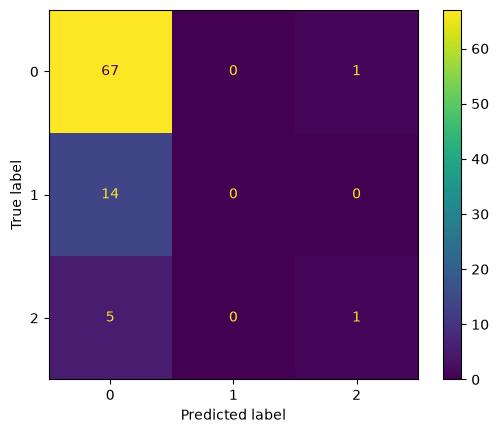

In [ ]:
confusion_mtx = confusion_matrix(true_labels, predicted_labels)
ConfusionMatrixDisplay(confusion_matrix=confusion_mtx, display_labels=[0, 1, 2]).plot()

In [ ]:
val_data["CDR"].value_counts(normalize=True)

CDR
0    0.771429
1    0.157143
2    0.071429
Name: proportion, dtype: float64

In [ ]:
from collections import Counter

print("True labels:", Counter(true_labels))
print("Predicted:", Counter(predicted_labels))

True labels: Counter({np.float32(0.0): 68, np.float32(1.0): 14, np.float32(2.0): 6})
Predicted: Counter({np.int64(0): 86, np.int64(2): 2})
